# A/B-тест e-mail рассылки (Hillstrom)

Интернет-магазин одежды разослал письма: 64 000 клиентов случайно разделили на три группы. Первой отправили письмо с мужской коллекцией, второй с женской, третьей ничего. Две недели смотрели, кто зашёл на сайт, кто купил и на сколько.

Вопрос: работает ли рассылка, какое письмо лучше и стоит ли слать его всем.

In [1]:
from sklift.datasets import fetch_hillstrom
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import TTestIndPower, NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest, proportion_confint
from statsmodels.stats.weightstats import ztest

import ab

sns.set_theme(style = 'whitegrid')

In [2]:
alpha = 0.05
beta = 0.2
rng = np.random.default_rng(42)

## Шаг 0. Знакомство с данными

In [3]:
dataset = fetch_hillstrom(target_col='all')
data, target, treatment = dataset.data, dataset.target, dataset.treatment

Данные приходят тремя таблицами:

- `data`: что известно о клиенте до теста
- `treatment`: в какую группу попал клиент (назначение)
- `target`: что произошло за 2 недели после рассылки

In [4]:
data.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
dtypes: float64(1), int64(4), object(3)
memory usage: 3.9+ MB


In [6]:
target.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   visit       64000 non-null  int64  
 1   conversion  64000 non-null  int64  
 2   spend       64000 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 1.5 MB


In [7]:
treatment.info()

<class 'pandas.core.series.Series'>
RangeIndex: 64000 entries, 0 to 63999
Series name: segment
Non-Null Count  Dtype 
--------------  ----- 
64000 non-null  object
dtypes: object(1)
memory usage: 500.1+ KB


Пропусков нет, типы правильные.

### Признаки до теста

- `recency`: сколько месяцев прошло с последней покупки, от 1 до 12
- `history`: сколько клиент потратил за последний год, \$
- `history_segment`: те же траты, но нарезанные на 7 корзин
- `mens`, `womens`: покупал ли мужское / женское за последний год (0/1)
- `newbie`: 1, если клиент новый (пришёл в течение последнего года)
- `zip_code`: где живёт клиент: город, пригород, село
- `channel`: где покупал: Phone, Web, Multichannel

In [8]:
data.describe()

,recency,history,mens,womens,newbie
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250
std,3.507592,256.158608,0.497393,0.497526,0.499999
min,1.000000,29.990000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000


In [9]:
data.describe(include='object')

,history_segment,zip_code,channel
count,64000,64000,64000
unique,7,3,3
top,1) $0 - $100,Surburban,Web
freq,22970,28776,28217


In [10]:
data['history_segment'].value_counts().sort_index()

history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64

In [11]:
data['zip_code'].value_counts()

zip_code
Surburban    28776
Urban        25661
Rural         9563
Name: count, dtype: int64

В `zip_code` опечатка: `Surburban` вместо `Suburban`. Ошибка во всех строках этой категории, на смысл не влияет, но значение пойдёт в таблицы и графики, поэтому исправляем.

In [12]:
data['zip_code'] = data['zip_code'].str.replace('Surburban', 'Suburban')
data['zip_code'].value_counts()

zip_code
Suburban    28776
Urban       25661
Rural        9563
Name: count, dtype: int64

Пригород > город > село. Насколько равномерно они легли по группам, проверим на шаге 2.

In [13]:
data['channel'].value_counts()

channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64

### Группы

In [14]:
treatment.value_counts()

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Три группы примерно равны, разница меньше 1%. Формально проверим это хи-квадратом (SRM) на шаге 2.

Дальше удобнее работать с одной таблицей.

In [15]:
df = pd.concat([data, target, treatment], axis=1)
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,visit,conversion,spend,segment
0,10,2) $100 - $200,142.44,1,0,Suburban,0,Phone,0,0,0.0,Womens E-Mail
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,0,0,0.0,No E-Mail
2,7,2) $100 - $200,180.65,0,1,Suburban,1,Web,0,0,0.0,Womens E-Mail
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,0,0,0.0,Mens E-Mail
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,0,0,0.0,Womens E-Mail


### Проверки логики

In [16]:
((df['conversion'] == 1) == (df['spend'] > 0)).all()

np.True_

`conversion = 1` ровно тогда, когда `spend > 0`. Нет ни покупок без трат, ни трат без покупки.

In [17]:
df[df['conversion'] == 1]['visit'].min()

np.int64(1)

Все купившие заходили на сайт (`visit = 1`). Значит, исходов всего три вида: не зашёл, зашёл без покупки, зашёл и купил.

In [18]:
((df['mens'] == 0) & (df['womens'] == 0)).sum()

np.int64(0)

Клиентов, которые не покупали ни мужское, ни женское, нет: у каждого есть хотя бы одна пометка.

Проверяем, что `history_segment` согласуется с `history`: сами относим клиента к корзине по `history` и сравниваем с номером сегмента.

In [19]:
def hist_segment(value):
    if value < 100:
        return '1'
    elif value < 200:
        return '2'
    elif value < 350:
        return '3'
    elif value < 500:
        return '4'
    elif value < 750:
        return '5'
    elif value < 1000:
        return '6'
    else:
        return '7'

my_segment = df['history'].apply(hist_segment)
(my_segment != df['history_segment'].str[0]).sum()

np.int64(0)

Все строки совпали. Граница включается в верхний сегмент: клиент с `history = 100` попадает во 2-й сегмент \$100 - \$200. Новой информации `history_segment` не несёт, это просто `history` по корзинам.

### Исходы теста

In [20]:
df[['visit', 'conversion']].mean() * 100

visit         14.678125
conversion     0.903125
dtype: float64

На сайт за 2 недели зашли около 14.7% клиентов, купили только 0.9%. Покупка очень редкое событие.

In [21]:
df.groupby('segment')[['visit', 'conversion', 'spend']].mean()

,visit,conversion,spend
segment,,,
Mens E-Mail,0.182757,0.012531,1.422617
No E-Mail,0.106167,0.005726,0.652789
Womens E-Mail,0.151400,0.008837,1.077202


В обеих группах с рассылкой визиты, конверсия и выручка на клиента выше, чем в контроле (конверсия 1.25% и 0.88% против 0.57%). Но выводов пока не делаем: значимость проверим на шаге 3.

In [22]:
(df['spend'] == 0).mean() * 100

np.float64(99.096875)

У 99.1% клиентов `spend = 0`. Значит, средняя выручка на клиента почти целиком определяется 578 покупателями.

In [23]:
buyers = df[df['spend'] > 0]
buyers['spend'].describe()

count    578.000000
mean     116.363547
std      107.871537
min       29.990000
25%       32.272500
50%       80.795000
75%      153.350000
max      499.000000
Name: spend, dtype: float64

In [24]:
buyers['spend'].value_counts().head()

spend
29.99     136
499.00     12
65.49       2
362.20      2
83.26       2
Name: count, dtype: int64

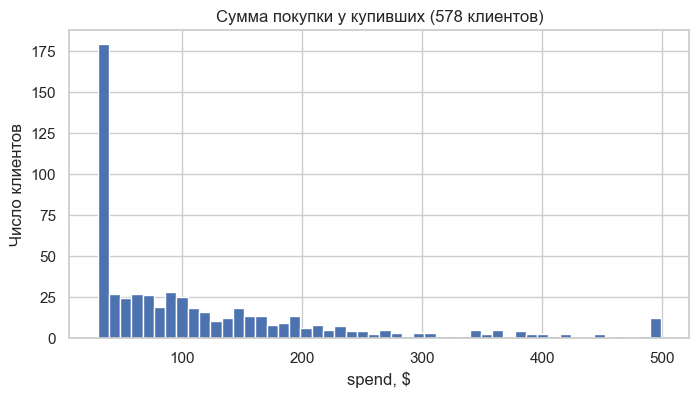

In [25]:
plt.figure(figsize=(8, 4))
plt.hist(buyers['spend'], bins=50)
plt.title('Сумма покупки у купивших (578 клиентов)')
plt.xlabel('spend, $')
plt.ylabel('Число клиентов')
plt.savefig('images/spend_hist.png', dpi=150, bbox_inches='tight')
plt.show()

Распределение сильно скошено вправо: обычно тратят мало, медиана около \$81, но есть хвост до \$499. Две особенности: 136 покупок ровно на \$29.99 (видимо, одна дешёвая позиция) и 12 ровно на \$499, выше которого нет ни одной, похоже на потолок в данных.

### Дубликаты

In [26]:
df.duplicated().sum()

np.int64(6562)

In [27]:
df.duplicated(keep=False).sum()

np.int64(7634)

In [28]:
dups = df[df.duplicated(keep=False)]
dups.value_counts().reset_index(name='repeats').head(10)

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,visit,conversion,spend,segment,repeats
0,10,1) $0 - $100,29.99,0,1,Suburban,1,Phone,0,0,0.0,Mens E-Mail,31
1,10,1) $0 - $100,29.99,1,0,Suburban,0,Web,0,0,0.0,Womens E-Mail,27
2,10,1) $0 - $100,29.99,1,0,Suburban,0,Phone,0,0,0.0,No E-Mail,27
3,10,1) $0 - $100,29.99,0,1,Urban,1,Phone,0,0,0.0,Womens E-Mail,27
4,10,1) $0 - $100,29.99,1,0,Suburban,1,Phone,0,0,0.0,No E-Mail,26
5,10,1) $0 - $100,29.99,1,0,Suburban,1,Web,0,0,0.0,No E-Mail,26
6,10,1) $0 - $100,29.99,0,1,Urban,0,Web,0,0,0.0,Womens E-Mail,25
7,9,1) $0 - $100,29.99,1,0,Suburban,1,Web,0,0,0.0,No E-Mail,25
8,10,1) $0 - $100,29.99,1,0,Urban,0,Web,0,0,0.0,Womens E-Mail,25
9,10,1) $0 - $100,29.99,0,1,Suburban,1,Web,0,0,0.0,Mens E-Mail,25


6562 строки являются повторами более ранних. Всего в повторах участвуют 7634 строки, это 1072 разных профиля.

In [29]:
dups['history_segment'].value_counts()

history_segment
1) $0 - $100      7606
2) $100 - $200      18
3) $200 - $350       6
5) $500 - $750       4
Name: count, dtype: int64

In [30]:
(dups['history'] == 29.99).mean() * 100

np.float64(99.16164527115536)

In [31]:
dups['conversion'].sum()

np.int64(0)

Почти все дубли (99%) это клиенты с `history = 29.99`, то есть купившие за год одну самую дешёвую вещь. Остальные признаки почти все двоичные или с парой значений, а id клиента в данных нет, поэтому такие клиенты неизбежно совпадают целиком. Среди дублей нет ни одной покупки: у купивших `spend` с копейками, совпасть им почти невозможно.

Это разные клиенты с похожими профилями, а не ошибка выгрузки. Удалять их нельзя: так мы выкинем реальных клиентов и сломаем случайное разбиение на группы.

### Решения по данным

1. Исправили опечатку в `zip_code`: `Surburban` -> `Suburban`.
2. Дубликаты оставляем: это разные клиенты с одинаковыми профилями, удаление сломает A/B-тест.
3. Противоречий в данных нет: `conversion` совпадает со `spend > 0`, все купившие заходили на сайт, `history_segment` согласуется с `history`, клиентов без `mens` и `womens` нет.
4. Конверсия очень редкая (0.57% в контроле). Эффекты будут маленькими в абсолютных цифрах, и их легко спутать со случайным шумом. Поэтому сначала считаем MDE: какой эффект тест вообще способен увидеть (шаг 1).
5. Выручка на клиента: 99% нулей и длинный правый хвост у купивших, значит, высокая дисперсия. Распределение совсем не симметричное, поэтому не очевидно, что t-тест тут корректен. Проверим это A/A-симуляциями (шаг 2) и сравним с bootstrap (шаг 4).
6. Колонки после теста (`visit`, `conversion`, `spend`) не используем как признаки или фильтры при сравнении групп, иначе будет утечка. Для проверки рандомизации, CUPED и сегментов берём только признаки до теста.

## Шаг 1. Дизайн теста

Представляем, что тест ещё не запущен: выбираем метрики и гипотезы и считаем, какой эффект тест вообще способен увидеть. Базовые значения метрик берём из контрольной группы.

### Метрики

- **Целевая: ARPU**, выручка на клиента за 2 недели (`spend` вместе с нулями). Она напрямую про деньги и учитывает сразу и сколько людей купили, и на сколько.
- **Конверсия в покупку** (`conversion`), второстепенная. Она может вырасти, а выручка нет: клиент зайдёт по письму и купит что-то дешёвое из рекомендаций, а не вещь из письма.
- **Конверсия в визит** (`visit`), второстепенная. Сама по себе не приносит денег, но это самая чувствительная метрика и проверка механизма: если письмо не привело даже визитов, дальше смотреть нечего.
- **ARPPU**, средний чек купивших, только для диагностики. Покупатели в группах после рассылки уже не случайные: если письмо привлекло новых покупателей с дешёвыми покупками, ARPPU упадёт, даже если остальные тратят столько же. Это ratio-метрика, её разберём bootstrap'ом на шаге 4.

ARPU это выручка, а не прибыль: стоимость письма и маржу учтём на шаге 6.

### Гипотезы и сравнения

Делаем три сравнения:

1. Мужское письмо против контроля
2. Женское письмо против контроля
3. Мужское письмо против женского, чтобы выбрать, какое слать

Для каждой пары групп A и B:

- H0: ARPU_A = ARPU_B
- H1: ARPU_A ≠ ARPU_B

Тест двусторонний, alpha = 0.05, мощность 0.8 (beta = 0.2).

### Поправка на множественные проверки

Если каждое из трёх сравнений проверять на уровне 0.05, шанс получить хотя бы одну ложную значимость (FWER) становится больше 5%, для независимых тестов до 1 - 0.95³ ≈ 14%. Поэтому нужна поправка.

- **Bonferroni**: каждое сравнение проверяем на уровне alpha / 3. FWER не выше 0.05, но поправка слишком строгая, теряем мощность.
- **Holm**: та же гарантия FWER ≤ 0.05, но отклоняет всё, что отклонил бы Bonferroni, и иногда больше. То есть мощнее при той же защите, и не требует независимости тестов.
- **Benjamini-Hochberg** контролирует не FWER, а FDR: долю ложных среди найденных эффектов. Подходит, когда тестов много и мы ищем идеи (возьмём её для сегментов на шаге 5). Требует независимости или положительной зависимости тестов.

Наши тесты зависимые: контроль участвует в двух сравнениях, мужское, как и женское письмо тоже. Сравнений всего три, и по ним принимается решение, поэтому берём **Holm**. Применяем его к целевой метрике, второстепенные смотрим без поправки, как поддержку.

### MDE

MDE (minimum detectable effect): самый маленький эффект, который тест найдёт с вероятностью 80% (это и есть мощность), если эффект действительно есть. Для двух групп по n клиентов:

$$MDE = (z_{1-\alpha/2} + z_{1-\beta}) \cdot \sigma \cdot \sqrt{2/n}$$

- z: квантили стандартного нормального распределения (1.96 и 0.84)
- σ: стандартное отклонение метрики. Для выручки это std `spend` в контроле, для долей √(p(1 - p))
- n: размер группы, около 21 300

Формула в `ab.MDE`.

In [32]:
control = df[df['segment'] == 'No E-Mail']

n = control.shape[0]
base_spend = control['spend'].mean()
std_spend = control['spend'].std(ddof=1)
p_conv = control['conversion'].mean()
p_visit = control['visit'].mean()

std_conv = np.sqrt(p_conv * (1 - p_conv))
std_visit = np.sqrt(p_visit * (1 - p_visit))

n, base_spend, std_spend, p_conv, p_visit

(21306,
 np.float64(0.6527893551112361),
 np.float64(11.588199681271533),
 np.float64(0.005726086548390125),
 np.float64(0.10616727682343002))

In [33]:
mde_spend = ab.MDE(alpha, beta, std_spend, n)
mde_conv = ab.MDE(alpha, beta, std_conv, n)
mde_visit = ab.MDE(alpha, beta, std_visit, n)

mde_spend / base_spend, mde_conv / p_conv, mde_visit / p_visit

(np.float64(0.4818487980967314),
 np.float64(0.35767776434878634),
 np.float64(0.07875908461957731))

#### Сверка со statsmodels

statsmodels возвращает не MDE, а стандартизированный эффект (эффект без единиц измерения):

- для выручки это d Коэна: d = MDE / σ, поэтому MDE = d · σ
- для долей это h Коэна: h = 2·arcsin(√p2) - 2·arcsin(√p1). Чтобы получить MDE, выражаем отсюда p2

In [34]:
d = TTestIndPower().solve_power(nobs1=n, alpha=alpha, power=1 - beta)
h = NormalIndPower().solve_power(nobs1=n, alpha=alpha, power=1 - beta)
d, h

(0.02714393819109383, 0.027143334249103368)

In [35]:
def p2_from_h(p1, h):
    return np.sin(np.arcsin(np.sqrt(p1)) + h / 2) ** 2

mde_spend_sm = d * std_spend
mde_conv_sm = p2_from_h(p_conv, h) - p_conv
mde_visit_sm = p2_from_h(p_visit, h) - p_visit

mde_spend_sm / base_spend, mde_conv_sm / p_conv, mde_visit_sm / p_visit

(np.float64(0.48185432778830795),
 np.float64(0.3894265065741828),
 np.float64(0.08011500633216861))

По выручке совпало. По долям наша формула даёт чуть меньший MDE, особенно по конверсии (36% против 39%). Причина в дисперсии: мы берём p(1 - p) контроля для обеих групп, а в тестовой группе p больше, и дисперсия тоже больше. Арксинус это учитывает. На визитах (p около 10%) разница почти незаметна, а на редкой конверсии видна.

Проверим, какая мощность на самом деле у нашего MDE по оценке statsmodels:

In [36]:
power_conv = NormalIndPower().power(proportion_effectsize(p_conv + mde_conv, p_conv), nobs1=n, alpha=alpha)
power_visit = NormalIndPower().power(proportion_effectsize(p_visit + mde_visit, p_visit), nobs1=n, alpha=alpha)
power_conv, power_visit

(np.float64(0.7353849048765014), np.float64(0.7866789963776618))

Для конверсии вместо 0.8 выходит около 0.74: на редких событиях простая формула немного оптимистична. Поэтому в итоговую таблицу для долей берём MDE через арксинус.

Ещё одна оговорка: поправка Holm в худшем случае проверяет первую гипотезу на уровне alpha / 3. Для целевой метрики посчитаем MDE и для этого случая.

In [37]:
mde_spend_holm = ab.MDE(alpha / 3, beta, std_spend, n)
mde_spend_holm / base_spend

np.float64(0.5564958220725926)

In [38]:
mde_table = pd.DataFrame({
    'метрика': ['ARPU, $', 'конверсия в покупку', 'конверсия в визит'],
    'база': [base_spend, p_conv, p_visit],
    'MDE абс.': [mde_spend, mde_conv_sm, mde_visit_sm],
    'MDE отн., %': [mde_spend / base_spend * 100, mde_conv_sm / p_conv * 100, mde_visit_sm / p_visit * 100],
})
mde_table.round(4)

,метрика,база,MDE абс.,"MDE отн., %"
0,"ARPU, $",0.6528,0.3145,48.1849
1,конверсия в покупку,0.0057,0.0022,38.9427
2,конверсия в визит,0.1062,0.0085,8.0115


MDE абс. для выручки в долларах на клиента, для долей в абсолютных долях (0.0022 = 0.22 процентного пункта).

### Обратная задача: сколько клиентов нужно

Из той же формулы выражаем n:

$$n = \frac{2 \cdot (z_{1-\alpha/2} + z_{1-\beta})^2 \cdot \sigma^2}{MDE^2}$$

Формула в `ab.n_for_test`. Сначала проверка «туда и обратно»: если подставить MDE, посчитанный для нашего n, должен вернуться тот же размер группы.

In [39]:
ab.n_for_test(alpha, beta, std_spend ** 2, mde_spend), n

(np.float64(21306.0), 21306)

Сколько клиентов нужно в каждой группе, чтобы увидеть рост ARPU на 10%:

In [40]:
n_10 = ab.n_for_test(alpha, beta, std_spend ** 2, 0.1 * base_spend)
n_10_sm = TTestIndPower().solve_power(effect_size=0.1 * base_spend / std_spend, alpha=alpha, power=1 - beta)
n_10, n_10_sm, n_10 / n

(np.float64(494680.0), 494678.7584654529, np.float64(23.21787289965268))

### Выводы по шагу 1

1. Целевая метрика ARPU, второстепенные конверсия в покупку и в визит, ARPPU только для диагностики. Три сравнения, поправка Holm на целевую метрику.
2. Визиты тест видит хорошо: заметен уже рост на 8% (с 10.6% до 11.5%).
3. Конверсию хуже: только рост примерно на 39%, с 0.57% до 0.80%. Для таких редких событий простая формула MDE немного оптимистична, точнее считать через арксинус.
4. Выручку хуже всего: ARPU должен вырасти почти в полтора раза (+48%, с \$0.65 до \$0.97 на клиента), а с поправкой Holm в худшем случае на 56%. Причина в 99% нулей и длинном хвосте: std выручки почти в 18 раз больше среднего.
5. Чтобы увидеть рост выручки на 10%, нужно около 495 тыс. клиентов в каждой группе, в 23 раза больше, чем у нас есть.

Итого по деньгам тест чувствителен только к крупным эффектам. Если по выручке разница окажется незначимой, это не значит, что письмо не работает: эффект меньше 48% тест просто не может увидеть.

## Шаг 2. Проверка рандомизации и A/A

На шаге 0 группы вышли почти одинаковыми по размеру. Проверим, нормально ли такое расхождение и похожи ли клиенты в трёх группах до отправки писем. Потом вернёмся к вопросу про выручку с кучей нулей и посмотрим, как на ней ведёт себя тест Уэлча.

### Размеры групп (SRM)

По плану в каждую группу должна была попасть треть клиентов. Посмотрим, сколько попало на самом деле.

In [41]:
group_counts = df.groupby('segment').size()
expected_count = group_counts.sum() / 3
pd.DataFrame({'Фактически': group_counts, 'Ожидалось': expected_count}).round(1)

,Фактически,Ожидалось
segment,,
Mens E-Mail,21307,21333.3
No E-Mail,21306,21333.3
Womens E-Mail,21387,21333.3


Ожидали примерно по 21 333 клиента. Считаем χ² сами и сверяем со SciPy. В обоих результатах сначала статистика, потом p-value.

In [42]:
srm = ab.custom_chisquare(group_counts.to_numpy())
srm, tuple(stats.chisquare(group_counts.to_numpy()))

((np.float64(0.20253125000000002), np.float64(0.9036929575604196)),
 (np.float64(0.20253125000000002), np.float64(0.9036929575604196)))

Совпало. p ≈ 0.90, так что разница в размерах вполне укладывается в случайное разбиение 1:1:1.

### Похожи ли клиенты до рассылки

Сравним, когда клиенты последний раз покупали и сколько тратили за год. Для `recency` и `history` берём средние и сравниваем их через ANOVA. Для остальных признаков смотрим доли внутри каждой группы и проверяем их χ²-тестом. У каждого признака свой p-value, даже если у него несколько строк в таблице.

In [43]:
numeric_features = {'recency': 'среднее, мес.', 'history': 'среднее, $'}
categorical_features = ['mens', 'womens', 'newbie', 'history_segment', 'zip_code', 'channel']
balance, balance_checks = ab.covariate_balance(df, 'segment', numeric_features, categorical_features)
balance.round(2)

Mens E-Mail  No E-Mail  Womens E-Mail  \
Признак         Значение                                                      
recency         среднее, мес.                5.77       5.75           5.77   
history         среднее, $                 242.84     240.88         242.54   
mens            0 (%)                       44.91      44.68          45.11   
                1 (%)                       55.09      55.32          54.89   
womens          0 (%)                       44.86      45.24          44.99   
                1 (%)                       55.14      54.76          55.01   
newbie          0 (%)                       49.85      49.80          49.68   
                1 (%)                       50.15      50.20          50.32   
history_segment 1) $0 - $100 (%)            36.25      35.73          35.69   
                2) $100 - $200 (%)          22.02      22.70          22.10   
                3) $200 - $350 (%)          19.20      18.98          19.43   
                4) $350 - $500 (%)           9.84       9.97          10.23   
                5) $500 - $750 (%)           7.50       7.75           7.77   
                6) $750 - $1,000 (%)         3.02       2.92           2.77   
                7) $1,000 + (%)              2.18       1.95           2.00   
zip_code        Rural (%)                   15.22      14.73          14.87   
                Suburban (%)                44.59      45.18          45.12   
                Urban (%)                   40.19      40.09          40.01   
channel         Multichannel (%)            12.09      12.23          12.06   
                Phone (%)                   43.37      43.78          44.20   
                Web (%)                     44.54      43.99          43.74   

                                     p-value  
Признак         Значение                      
recency         среднее, мес.          0.763  
history         среднее, $             0.698  
mens            0 (%)                  0.672  
                1 (%)                         
womens          0 (%)                  0.729  
                1 (%)                         
newbie          0 (%)                  0.934  
                1 (%)                         
history_segment 1) $0 - $100 (%)       0.358  
                2) $100 - $200 (%)            
                3) $200 - $350 (%)            
                4) $350 - $500 (%)            
                5) $500 - $750 (%)            
                6) $750 - $1,000 (%)          
                7) $1,000 + (%)               
zip_code        Rural (%)              0.579  
                Suburban (%)                  
                Urban (%)                     
channel         Multichannel (%)       0.458  
                Phone (%)                     
                Web (%)

In [44]:
balance_checks.round(6)

,Наша статистика,Статистика SciPy,Наш p-value,p-value SciPy
Признак,,,,
recency,0.270389,0.270389,0.763083,0.763083
history,0.359487,0.359487,0.698036,0.698036
mens,0.795994,0.795994,0.671664,0.671664
womens,0.632522,0.632522,0.728869,0.728869
newbie,0.136868,0.136868,0.933855,0.933855
history_segment,13.153292,13.153292,0.357998,0.357998
zip_code,2.871942,2.871942,0.579479,0.579479
channel,3.632402,3.632402,0.458034,0.458034


Свои расчёты со SciPy совпали. Последняя покупка была в среднем около 5.8 месяца назад во всех трёх группах. Средние траты за год лежат между \$241 и \$243, доли по категориям тоже близки.

Все восемь p-value выше 0.05. Если бы один оказался ниже порога, я бы сначала посмотрел на само различие: при нескольких проверках маленький p-value может попасться случайно.

### A/A на контроле

Помним, что у большинства клиентов `spend = 0`, а у нескольких покупки крупные. Проверим, как часто Уэлч находит разницу в выручке, когда никто не получал письма. Заодно проверим z-тест на визитах и покупках.

Берём только `No E-Mail` и 10 000 раз случайно делим контроль пополам. У каждого клиента в одном прогоне только одна группа. Перед симуляцией сравним свои тесты с библиотечными на одном разбиении для каждой метрики.

In [45]:
values_spend = control['spend'].to_numpy()
values_visit = control['visit'].to_numpy()
values_conversion = control['conversion'].to_numpy()
sample_size = len(control) // 2
n_iters = 10_000

In [46]:
aa_metrics = [
    ('ARPU', values_spend, ab.welch_for_aa, ab.welch_scipy),
    ('Визиты', values_visit, ab.custom_proportion_ztest, ab.prop_ztest_wrapper),
    ('Покупки', values_conversion, ab.custom_proportion_ztest, ab.prop_ztest_wrapper),
]

In [47]:
aa_p_values, aa_checks = ab.run_aa_checks(aa_metrics, sample_size, rng, n_iters)
aa_checks['ARPU']

((np.float64(0.09344851800030872), np.float64(0.9255481261130429)),
 (np.float64(0.09344851800030872), np.float64(0.9255481261130429)))

In [48]:
aa_checks['Визиты'], aa_checks['Покупки']

(((np.float64(-2.846659642176852), np.float64(0.004418057074851545)),
  (np.float64(-2.846659642176852), np.float64(0.004418057074851561))),
 ((np.float64(-0.5447764339465389), np.float64(0.5859072885332286)),
  (np.float64(-0.5447764339465389), np.float64(0.5859072885332286))))

Статистики и p-value совпали с SciPy и statsmodels. Теперь считаем долю прогонов с p < 0.05. В A/A это ложные срабатывания (FPR). Интервал Уилсона показывает, насколько точно 10 000 прогонов оценили эту долю на нашем контроле.

In [49]:
aa_rates = {name: ab.simulation_rate(p_values < alpha) for name, p_values in aa_p_values.items()}
rate_columns = ['Доля, %', 'Нижняя граница 95% ДИ, %', 'Верхняя граница 95% ДИ, %']
pd.DataFrame.from_dict(aa_rates, orient='index', columns=rate_columns).mul(100).round(2)

,"Доля, %","Нижняя граница 95% ДИ, %","Верхняя граница 95% ДИ, %"
ARPU,5.44,5.01,5.90
Визиты,4.80,4.40,5.24
Покупки,5.74,5.30,6.21


Визиты дали 4.80%, ARPU 5.44%. Для ARPU нижняя граница интервала едва выше 5%. На покупках превышение заметнее: 5.74%. Посмотрим ещё на распределения p-value.

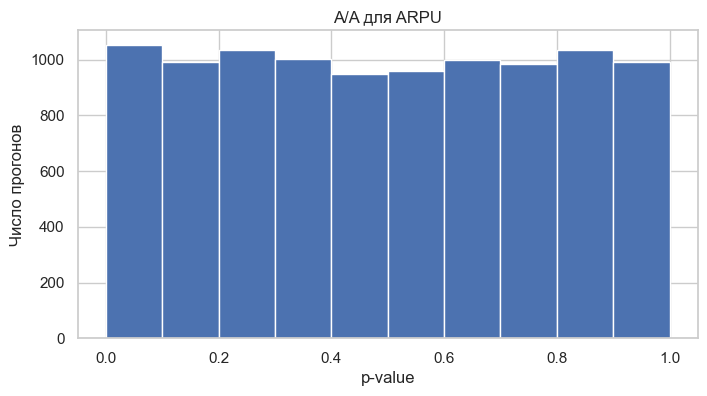

In [50]:
bins = np.linspace(0, 1, 11)
plt.figure(figsize=(8, 4))
plt.hist(aa_p_values['ARPU'], bins=bins, edgecolor='white')
plt.gca().set(title='A/A для ARPU', xlabel='p-value', ylabel='Число прогонов')
plt.savefig('images/aa_arpu_hist.png', dpi=150, bbox_inches='tight')

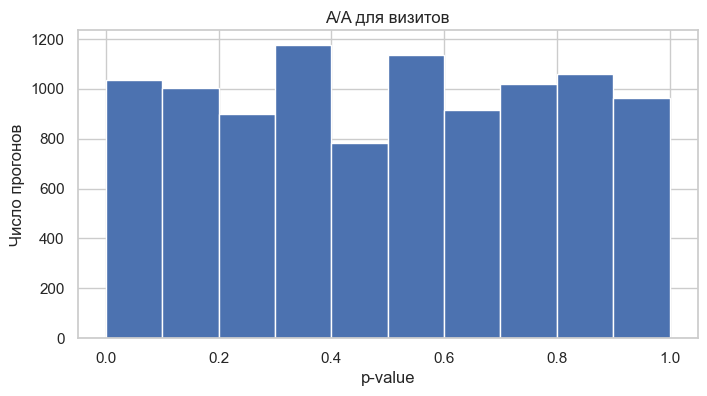

In [51]:
plt.figure(figsize=(8, 4))
plt.hist(aa_p_values['Визиты'], bins=bins, edgecolor='white')
plt.gca().set(title='A/A для визитов', xlabel='p-value', ylabel='Число прогонов')
plt.savefig('images/aa_visit_hist.png', dpi=150, bbox_inches='tight')

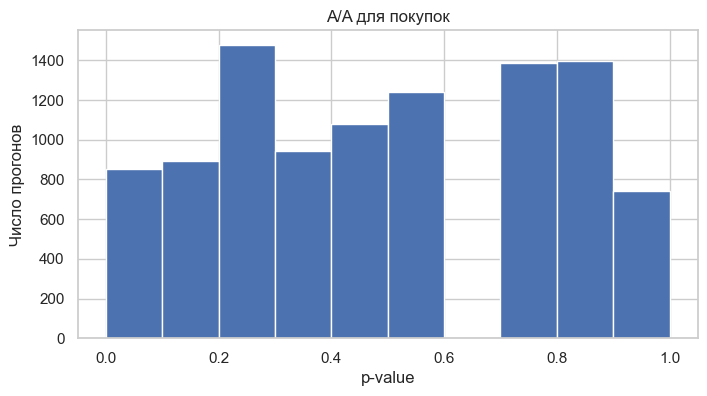

In [52]:
plt.figure(figsize=(8, 4))
plt.hist(aa_p_values['Покупки'], bins=bins, edgecolor='white')
plt.gca().set(title='A/A для покупок', xlabel='p-value', ylabel='Число прогонов')
plt.savefig('images/aa_conversion_hist.png', dpi=150, bbox_inches='tight')

У ARPU столбцы примерно одинаковой высоты. У покупок один интервал вообще пустой. Понятнее всего это видно, если отсортировать p-value и сравнить их с равномерной сеткой.

In [53]:
quantiles = (np.arange(n_iters) + 0.5) / n_iters
aa_quantiles = pd.DataFrame({name: np.sort(values) for name, values in aa_p_values.items()})
aa_quantiles['Равномерные p-value'] = quantiles

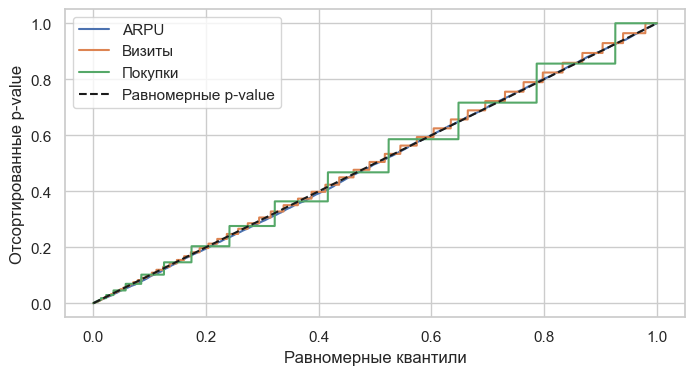

In [54]:
plt.figure(figsize=(8, 4))
plt.plot(quantiles, aa_quantiles.iloc[:, :3], quantiles, aa_quantiles.iloc[:, 3], 'k--')
plt.gca().set(xlabel='Равномерные квантили', ylabel='Отсортированные p-value')
plt.legend(aa_quantiles.columns)
plt.savefig('images/aa_p_value_quantiles.png', dpi=150, bbox_inches='tight')

Ступеньки у визитов и покупок получаются из-за повторов. В контроле всего 122 покупки, и разбиения с тем же числом покупок в каждой половине дают один и тот же p-value. После сортировки такие значения встают рядом. Для ARPU возможных значений гораздо больше: там важны и суммы покупок.

### Синтетический A/B для ARPU

А если разница есть? На шаге 1 считали MDE для групп примерно по 21 300 клиентов. Сейчас половинки по 10 653, поэтому пересчитаем эффект, который рассчитываем находить в 80% прогонов при p < 0.05.

In [55]:
effect = ab.MDE(alpha, beta, std_spend, sample_size)
round(effect, 3)

np.float64(0.445)

Выходит около \$0.445 на клиента. В каждом прогоне прибавляем эту сумму к `spend` всех клиентов второй половины, в том числе тех, кто ничего не купил. Так мы можем задать точный сдвиг ARPU. Для этой проверки берём простой сценарий, где прибавка у всех одна и та же.

In [56]:
p_values_ab = ab.run_synthetic_experiments(
    values_spend, sample_size, rng, ab.welch_for_aa, effect=effect, n_iters=n_iters,
)
p_values_aa = aa_p_values['ARPU']

In [57]:
simulation_rates = {'FPR (A/A)': aa_rates['ARPU']}
simulation_rates['FNR (A/B)'] = ab.simulation_rate(p_values_ab >= alpha)
simulation_rates['Мощность (A/B)'] = ab.simulation_rate(p_values_ab < alpha)
pd.DataFrame.from_dict(simulation_rates, orient='index', columns=rate_columns).mul(100).round(2)

,"Доля, %","Нижняя граница 95% ДИ, %","Верхняя граница 95% ДИ, %"
FPR (A/A),5.44,5.01,5.90
FNR (A/B),20.86,20.07,21.67
Мощность (A/B),79.14,78.33,79.93


Мощность вышла 79.14%, чуть ниже расчётных 80%. Верхняя граница интервала почти доходит до 80%. Посмотрим на обе кривые вместе: берём порог по X и считаем, какая доля p-value оказалась левее него. При пороге 0.05 на кривой A/A читаем FPR, а на A/B читаем мощность. Чёрная точка отмечает целевые 80% при этом пороге.

In [58]:
thresholds = np.unique(np.append(np.linspace(0, 1, 501), alpha))
ab_curves = pd.DataFrame({'A/A': [(p_values_aa < x).mean() for x in thresholds]}, index=thresholds)
ab_curves['Синтетический A/B'] = [(p_values_ab < x).mean() for x in thresholds]
ab_curves['Равномерные p-value'] = thresholds

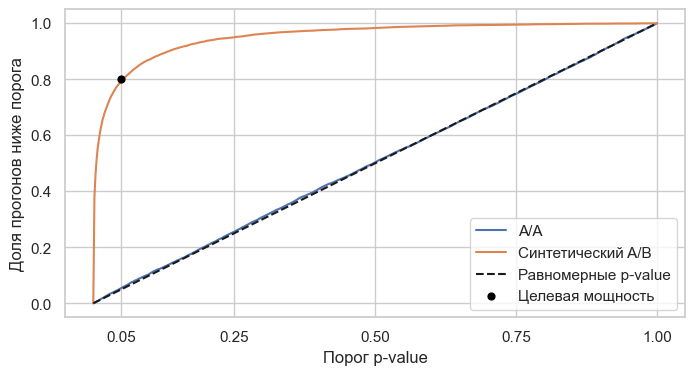

In [59]:
plt.figure(figsize=(8, 4)).gca().set(xlabel='Порог p-value', ylabel='Доля прогонов ниже порога', xticks=[alpha, 0.25, 0.5, 0.75, 1])
plt.plot(ab_curves.index, ab_curves.iloc[:, :2], ab_curves.index, ab_curves.iloc[:, 2], 'k--')
plt.scatter(alpha, 1 - beta, color='black', s=24, zorder=3)
plt.legend([*ab_curves.columns, 'Целевая мощность'])
plt.savefig('images/aa_ab_arpu.png', dpi=150, bbox_inches='tight')

### Выводы по шагу 2

1. Размеры групп укладываются в разбиение 1:1:1. По восьми признакам до рассылки заметных различий не нашли.
2. В A/A на этом контроле ложных срабатываний около 5% для визитов и ARPU. У покупок доля выше: 5.74%.
3. При сдвиге ARPU на \$0.445 тест Уэлча сработал в 79.14% прогонов. Это близко к расчётным 80% для такого размера групп и выбранной модели эффекта.